In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load and prepare df from the parent folder
df = pd.read_csv("../spotify_top_1000_tracks.csv", encoding="utf-8")
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year.fillna(0).astype(int)

                                          track_name                 artist  \
710                                         Lost Boy                  Jaden   
610                                I'm Getting Ready    Tasha Cobbs Leonard   
64                                           Mirrors      Justin Timberlake   
63   What Goes Around.../...Comes Around (Interlude)      Justin Timberlake   
622                               Achilles Come Down         Gang of Youths   
689                             Never Let Go (Of Me)                 Baltra   
682            House Of Balloons / Glass Table Girls             The Weeknd   
549                                             Stan                 Eminem   
671                                        Galvanize  The Chemical Brothers   
37                                       After Hours             The Weeknd   

     duration_min  
710      9.497883  
610      8.436667  
64       8.069100  
63       7.476217  
622      7.035767  
689      6

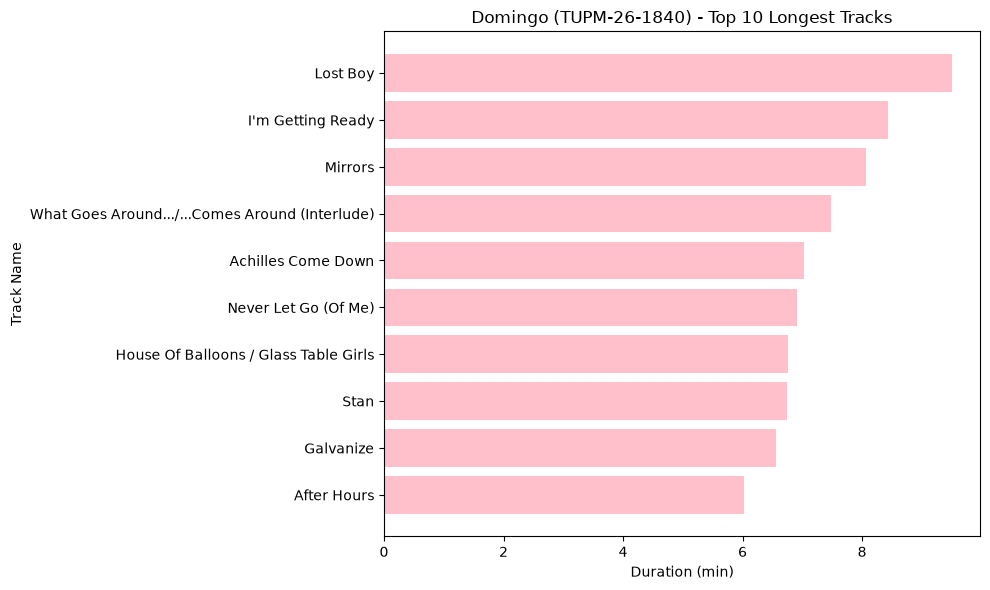

In [5]:
import matplotlib.pyplot as plt

student_name = "Domingo"
student_id = "TUPM-26-1840"
color_bar = "pink"

# Sort by duration_min descending and select top 10
top10_longest = df.sort_values(by='duration_min', ascending=False).head(10)

# Display table of track name, artist, and duration
print(top10_longest[['track_name', 'artist', 'duration_min']])

# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(top10_longest['track_name'], top10_longest['duration_min'], color=color_bar)
plt.xlabel('Duration (min)')
plt.ylabel('Track Name')
plt.title(f"{student_name} ({student_id}) - Top 10 Longest Tracks")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

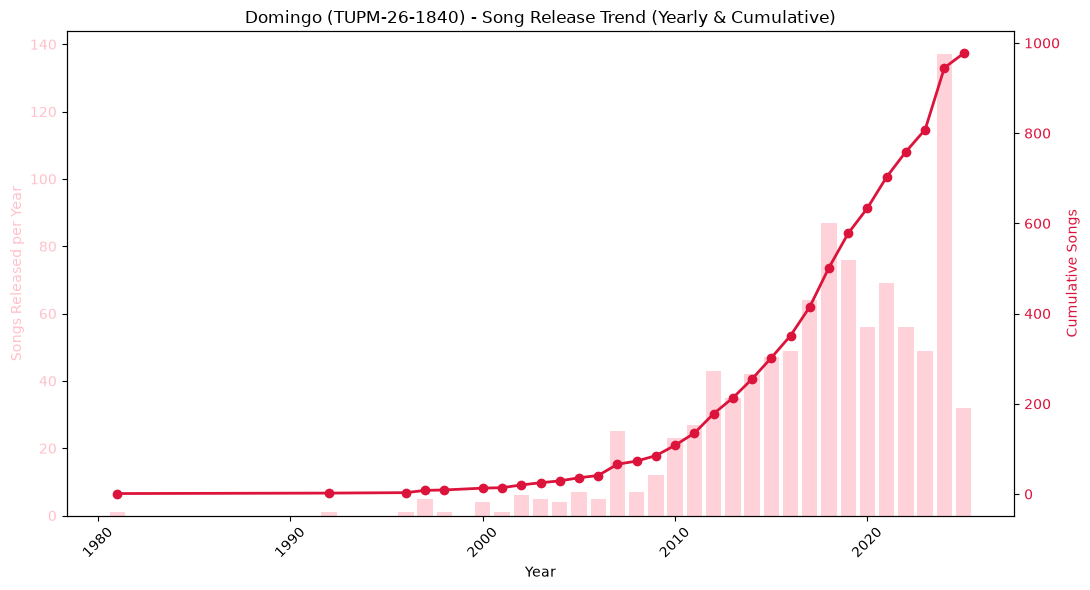

In [7]:
import matplotlib.pyplot as plt

student_name = "Domingo"
student_id = "TUPM-26-1840"
color_bar = "pink"
color_line = "crimson"

# Group by year, count songs released, and calculate cumulative song count
yearly_counts = (
    df[df['year'] > 0]
    .groupby('year')
    .size()
    .reset_index(name='song_count')
    .sort_values('year')
)
yearly_counts['cumulative_count'] = yearly_counts['song_count'].cumsum()

fig, ax1 = plt.subplots(figsize=(11, 6))

# Plot yearly counts as bars
ax1.bar(
    yearly_counts['year'],
    yearly_counts['song_count'],
    color=color_bar,
    alpha=0.7,
    label='Yearly Releases'
)
ax1.set_xlabel('Year')
ax1.set_ylabel('Songs Released per Year', color=color_bar)
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.tick_params(axis='x', rotation=45)

# Plot cumulative song count as a line on a secondary y-axis
ax2 = ax1.twinx()
ax2.plot(
    yearly_counts['year'],
    yearly_counts['cumulative_count'],
    color=color_line,
    marker='o',
    linewidth=2,
    label='Cumulative Total'
)
ax2.set_ylabel('Cumulative Songs', color=color_line)
ax2.tick_params(axis='y', labelcolor=color_line)

plt.title(f"{student_name} ({student_id}) - Song Release Trend (Yearly & Cumulative)")
fig.tight_layout()
plt.show()

In [8]:
import os
import webbrowser
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

student_name = "Domingo"
student_id = "TUPM-26-1840"
cmap_color = "plasma"

# Keep valid rows with year, duration_min, and popularity
df_anim = df.dropna(subset=['year', 'duration_min', 'popularity']).copy()
df_anim = df_anim[df_anim['year'] > 0]
years = sorted(df_anim['year'].unique())

fig, ax = plt.subplots(figsize=(9, 6))
x_min, x_max = df_anim['duration_min'].min(), df_anim['duration_min'].max()
y_min, y_max = df_anim['popularity'].min(), df_anim['popularity'].max()

def update(year):
    ax.clear()
    subset = df_anim[df_anim['year'] <= year]
    hb = ax.hexbin(
        subset['duration_min'],
        subset['popularity'],
        gridsize=20,
        cmap=cmap_color,
        mincnt=1
    )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Duration (min)')
    ax.set_ylabel('Popularity')
    ax.set_title(f"{student_name} ({student_id}) - Duration vs Popularity Density (Up to {int(year)})")
    return hb,

ani = FuncAnimation(fig, update, frames=years, interval=200, repeat=False)

gif_path = os.path.abspath("duration_popularity_density.gif")
ani.save(gif_path, writer=PillowWriter(fps=5))
print(f"GIF saved successfully at: {gif_path}")

webbrowser.open(f"file://{gif_path}")
plt.close(fig)

GIF saved successfully at: /Users/ehralizdomingo/Lab8_Data_Visualization_Domingo/Additional_Exercises_Lab8/duration_popularity_density.gif
